1. Concept: Image noise
Noise means random variations in pixel intensity. We add noise to an image to simulate disturbances that can occur during image capture or transmission.
The five noise distributions

1. Uniform noise

Every value within a specified interval is equally likely. Its histogram ideally looks flat.




2. Gaussian noise

Values near the mean occur more frequently than extreme values. Its histogram resembles a bell curve.




3. Erlang noise

A positive-valued distribution determined by a shape parameter \(k\) and rate parameter \(\lambda\). It is a special case of the Gamma distribution when \(k\) is a positive integer.




4. Exponential noise

Positive values are generated, with small values occurring more frequently than large values. Its histogram generally decreases from left to right.




5. Rayleigh noise

A positive-valued distribution that starts near zero, rises to a peak, and then decreases.

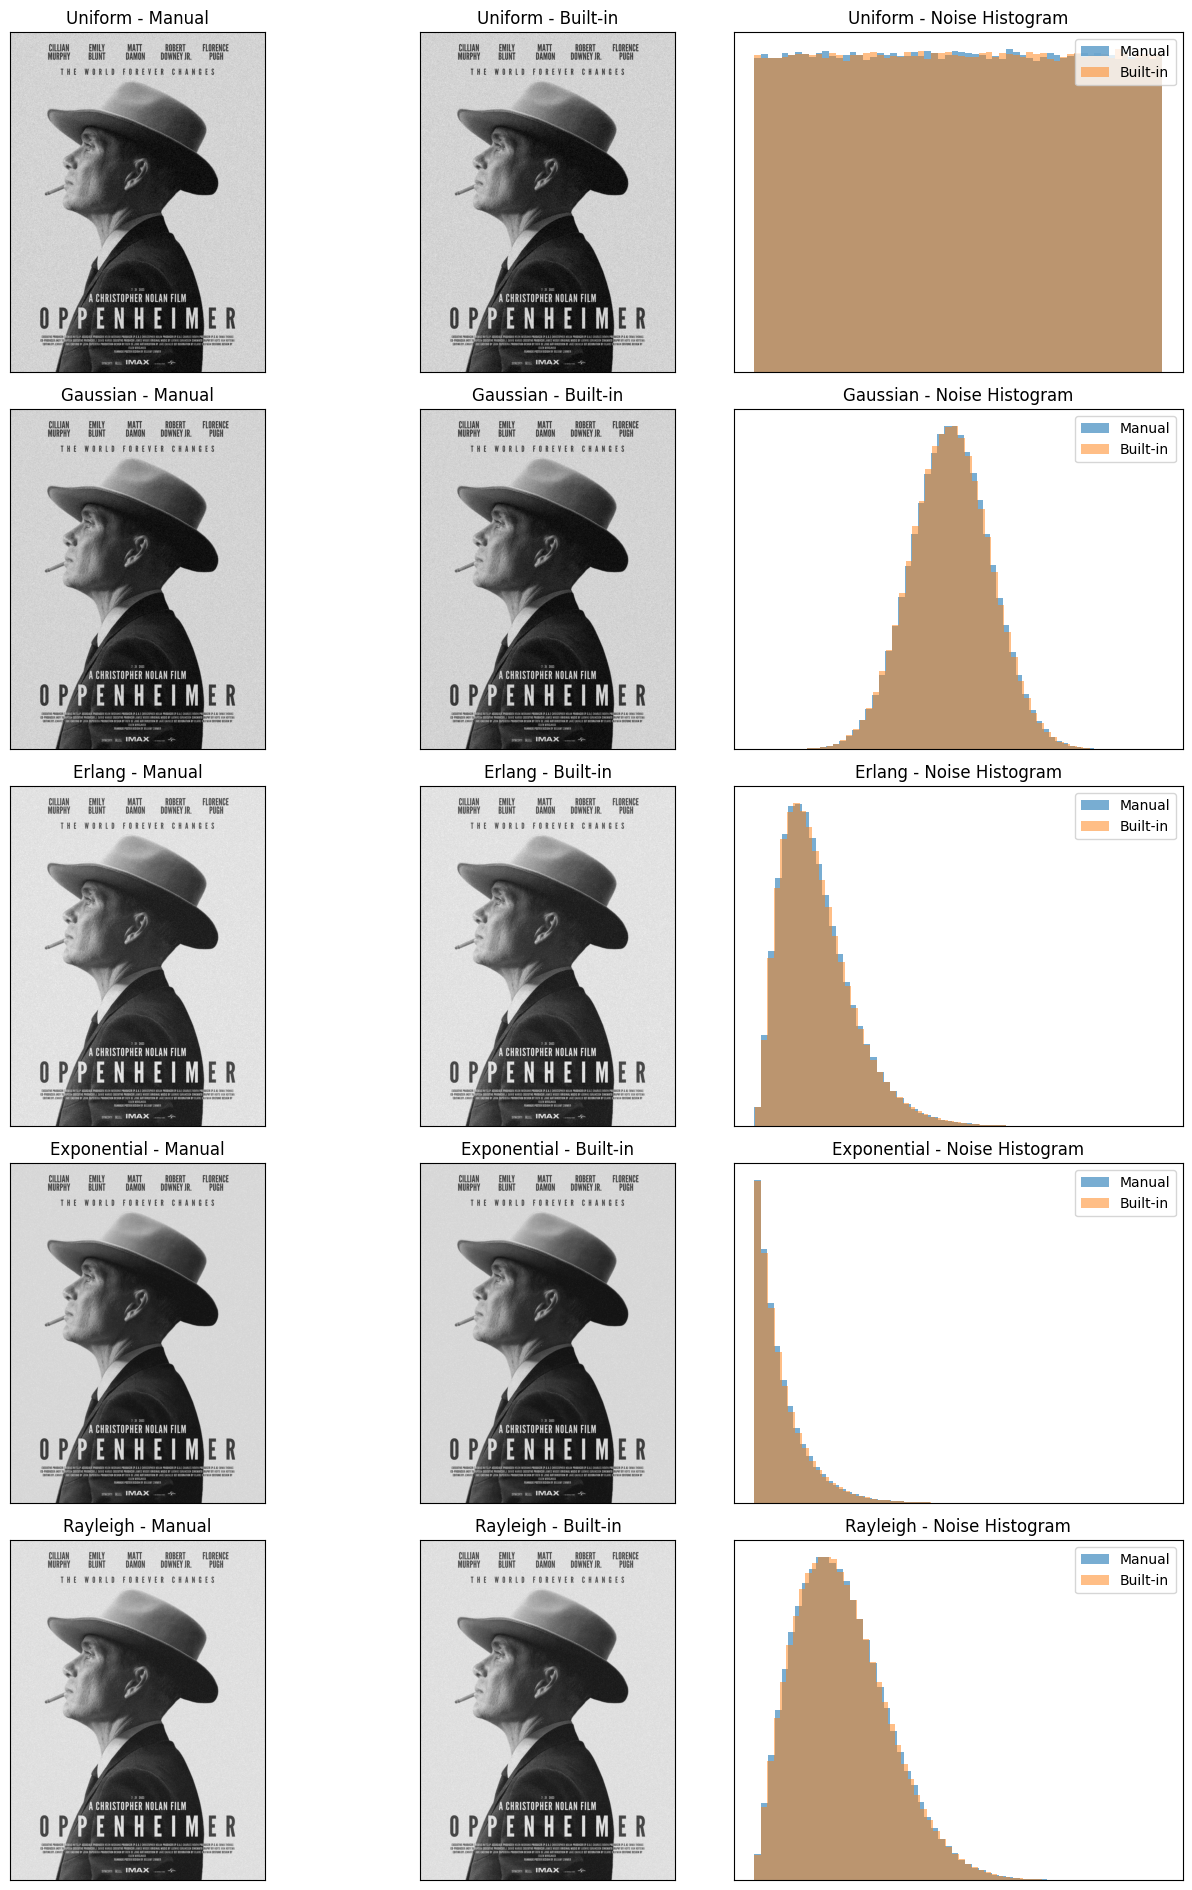

In [2]:
# python code - without opencv
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Read grayscale image
img = np.array(
    Image.open("abc.jpg").convert("L"),
    dtype=np.float64
)

rng = np.random.default_rng(42)
shape = img.shape

# Parameters
a, b = -20, 20            # Uniform limits
mu, sigma_g = 0, 10       # Gaussian mean and standard deviation
k, rate = 3, 0.2          # Erlang shape and rate
rate_e = 0.2              # Exponential rate
sigma_r = 10              # Rayleigh scale


# 1. UNIFORM NOISE
u = rng.random(shape)
uniform_manual = a + (b - a) * u
uniform_builtin = rng.uniform(a, b, shape)


# 2. GAUSSIAN NOISE (Box-Muller method)
u1 = np.maximum(rng.random(shape), 1e-12)
u2 = rng.random(shape)

z = np.sqrt(-2 * np.log(u1)) * np.cos(2 * np.pi * u2)
gaussian_manual = mu + sigma_g * z
gaussian_builtin = rng.normal(mu, sigma_g, shape)


# 3. ERLANG NOISE (sum of k exponential variables)
u = np.maximum(rng.random((k, *shape)), 1e-12)
erlang_manual = -np.sum(np.log(u), axis=0) / rate
erlang_builtin = rng.gamma(
    shape=k, scale=1 / rate, size=shape
)


# 4. EXPONENTIAL NOISE (inverse CDF)
u = np.maximum(rng.random(shape), 1e-12)
exponential_manual = -np.log(u) / rate_e
exponential_builtin = rng.exponential(
    scale=1 / rate_e, size=shape
)


# 5. RAYLEIGH NOISE (inverse CDF)
u = np.maximum(rng.random(shape), 1e-12)
rayleigh_manual = sigma_r * np.sqrt(-2 * np.log(u))
rayleigh_builtin = rng.rayleigh(
    scale=sigma_r, size=shape
)


# Collect results
results = [
    ("Uniform", uniform_manual, uniform_builtin),
    ("Gaussian", gaussian_manual, gaussian_builtin),
    ("Erlang", erlang_manual, erlang_builtin),
    ("Exponential", exponential_manual, exponential_builtin),
    ("Rayleigh", rayleigh_manual, rayleigh_builtin)
]


# Display noisy images and histograms
fig, axes = plt.subplots(5, 3, figsize=(13, 19))

for i, (name, manual, builtin) in enumerate(results):

    # Add noise to image and clip intensities to [0, 255]
    noisy_manual = np.clip(img + manual, 0, 255)
    noisy_builtin = np.clip(img + builtin, 0, 255)

    axes[i, 0].imshow(
        noisy_manual, cmap="gray", vmin=0, vmax=255
    )
    axes[i, 0].set_title(name + " - Manual")

    axes[i, 1].imshow(
        noisy_builtin, cmap="gray", vmin=0, vmax=255
    )
    axes[i, 1].set_title(name + " - Built-in")

    # Compare distributions of generated noise itself
    axes[i, 2].hist(
        manual.ravel(), bins=60, density=True,
        alpha=0.6, label="Manual"
    )
    axes[i, 2].hist(
        builtin.ravel(), bins=60, density=True,
        alpha=0.5, label="Built-in"
    )
    axes[i, 2].set_title(name + " - Noise Histogram")
    axes[i, 2].legend()

    for j in range(3):
        axes[i, j].set_xticks([])
        axes[i, j].set_yticks([])

plt.tight_layout()
plt.show()

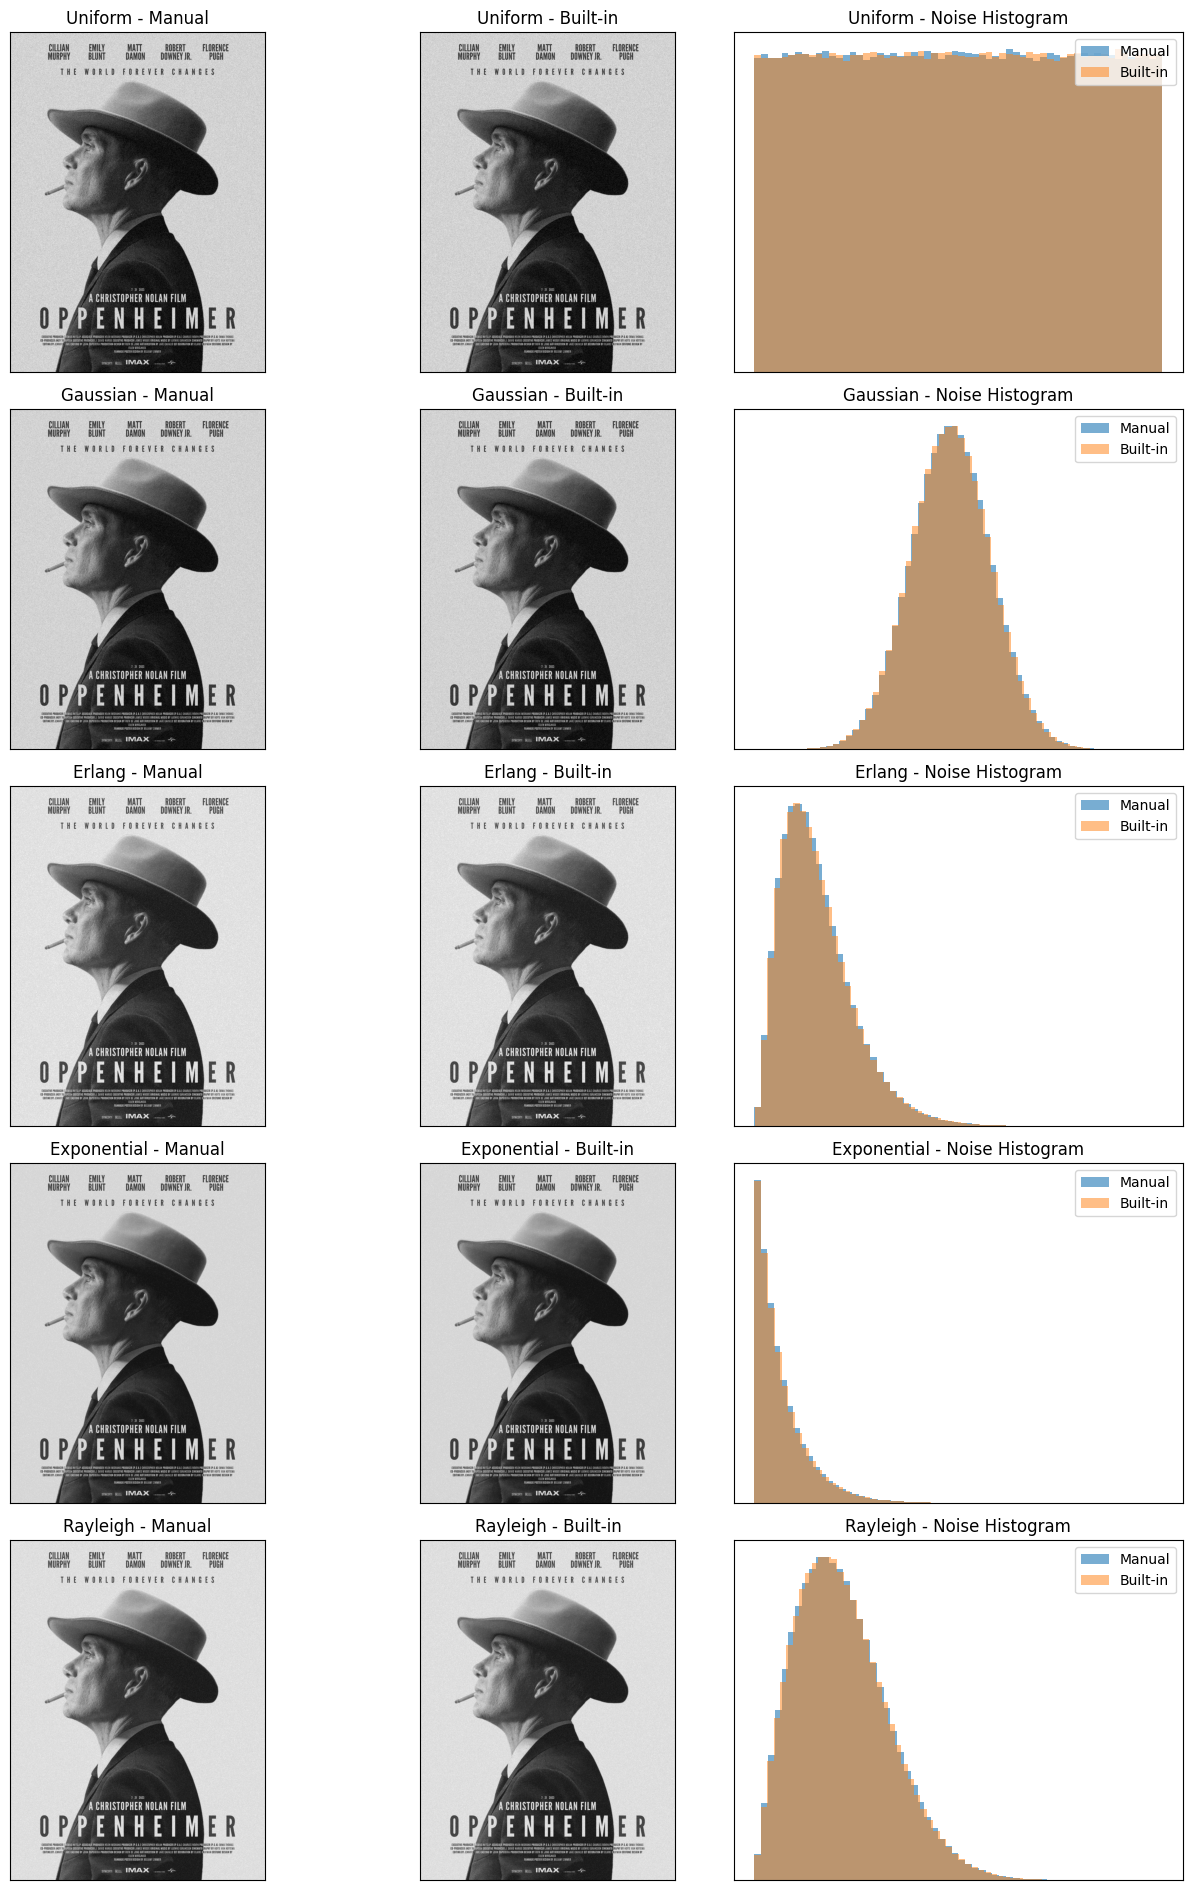

In [3]:
# openCV
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read grayscale image using OpenCV
img = cv2.imread("abc.jpg", cv2.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError("Check the image path.")

img = img.astype(np.float64)
shape = img.shape
rng = np.random.default_rng(42)

# Parameters
a, b = -20, 20
mu, sigma_g = 0, 10
k, rate = 3, 0.2
rate_e = 0.2
sigma_r = 10

# 1. UNIFORM NOISE
u = rng.random(shape)
uniform_manual = a + (b - a) * u
uniform_builtin = rng.uniform(a, b, shape)

# 2. GAUSSIAN NOISE
u1 = np.maximum(rng.random(shape), 1e-12)
u2 = rng.random(shape)

z = np.sqrt(-2 * np.log(u1)) * np.cos(2 * np.pi * u2)
gaussian_manual = mu + sigma_g * z
gaussian_builtin = rng.normal(mu, sigma_g, shape)

# 3. ERLANG NOISE
u = np.maximum(rng.random((k, *shape)), 1e-12)
erlang_manual = -np.sum(np.log(u), axis=0) / rate
erlang_builtin = rng.gamma(k, 1 / rate, shape)

# 4. EXPONENTIAL NOISE
u = np.maximum(rng.random(shape), 1e-12)
exponential_manual = -np.log(u) / rate_e
exponential_builtin = rng.exponential(1 / rate_e, shape)

# 5. RAYLEIGH NOISE
u = np.maximum(rng.random(shape), 1e-12)
rayleigh_manual = sigma_r * np.sqrt(-2 * np.log(u))
rayleigh_builtin = rng.rayleigh(sigma_r, shape)

results = [
    ("Uniform", uniform_manual, uniform_builtin),
    ("Gaussian", gaussian_manual, gaussian_builtin),
    ("Erlang", erlang_manual, erlang_builtin),
    ("Exponential", exponential_manual, exponential_builtin),
    ("Rayleigh", rayleigh_manual, rayleigh_builtin)
]

# Display images and compare histograms
fig, axes = plt.subplots(5, 3, figsize=(13, 19))

for i, (name, manual, builtin) in enumerate(results):

    # Create noisy images
    noisy_manual = np.clip(img + manual, 0, 255).astype(np.uint8)
    noisy_builtin = np.clip(img + builtin, 0, 255).astype(np.uint8)

    axes[i, 0].imshow(
        noisy_manual, cmap="gray", vmin=0, vmax=255
    )
    axes[i, 0].set_title(name + " - Manual")

    axes[i, 1].imshow(
        noisy_builtin, cmap="gray", vmin=0, vmax=255
    )
    axes[i, 1].set_title(name + " - Built-in")

    # Histograms of noise values
    axes[i, 2].hist(
        manual.ravel(), bins=60, density=True,
        alpha=0.6, label="Manual"
    )
    axes[i, 2].hist(
        builtin.ravel(), bins=60, density=True,
        alpha=0.5, label="Built-in"
    )
    axes[i, 2].set_title(name + " - Noise Histogram")
    axes[i, 2].legend()

    for j in range(3):
        axes[i, j].set_xticks([])
        axes[i, j].set_yticks([])

plt.tight_layout()
plt.show()